# Lab 13 — Validating a Clinical Prediction Model
**AI in Healthcare · Unit IV · B.Tech AI, Third Year**

Run top to bottom. All TODOs are completed. Every ✍️ answer is written in a cell that **computes its numbers from this run**, so the text always matches the outputs above it.

## Setup

In [1]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # sklearn deprecation notice for penalty=None

SEED = 42
DATA_DIR = Path.cwd() / "lab13_data"
DATA_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 120)
print("scikit-learn", sklearn.__version__, "| data directory: ./lab13_data/")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

scikit-learn 1.6.1 | data directory: ./lab13_data/


In [2]:
# ---- UCI Heart Disease: four hospitals --------------------------------------------------
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
SITE_FILES = {"Cleveland": "processed.cleveland.data", "Budapest": "processed.hungarian.data",
              "Zurich": "processed.switzerland.data", "Long Beach": "processed.va.data"}
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
EXPECTED_ROWS = {"Cleveland": 303, "Budapest": 294, "Zurich": 123, "Long Beach": 200}

SITES = {}
for site, fname in SITE_FILES.items():
    path = DATA_DIR / fname
    if not path.exists():
        urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)        # 0 = no disease, 1-4 = disease present
    SITES[site] = df
    check(f"{site}: {len(df)} patients (expected {EXPECTED_ROWS[site]})", len(df) == EXPECTED_ROWS[site])

PASS  Cleveland: 303 patients (expected 303)
PASS  Budapest: 294 patients (expected 294)
PASS  Zurich: 123 patients (expected 123)
PASS  Long Beach: 200 patients (expected 200)


In [3]:
# ---- Synthetic clinic visits (hand-written generator; fictional patients) ---------------
def make_visits(seed=13, n_patients=500):
    """Each patient enrols on a random date and has 3-12 visits within the next two years.
    The 90-day admission label is drawn from a logistic model of the TRUE values, plus a
    patient-level 'frailty' that is never recorded. Visits end on 2024-09-30 so every visit
    has 90 days of follow-up. Planted features are documented in Part 2."""
    rng = np.random.default_rng(seed)
    start, last_visit = pd.Timestamp("2021-01-01"), pd.Timestamp("2024-09-30")
    span = (last_visit - start).days
    rows = []
    for pid in range(1, n_patients + 1):
        frailty = rng.normal()                       # unrecorded patient-level risk
        height = rng.normal(165, 9)
        weight0 = rng.normal(72, 13)
        age0 = rng.integers(40, 86)
        sbp0 = rng.normal(132, 15) + 4 * frailty
        hba1c0 = rng.normal(6.4, 1.0) + 0.3 * frailty
        enrol = int(rng.integers(0, span - 180))
        window = min(730, span - enrol)
        days = enrol + np.sort(rng.choice(window, rng.integers(3, 13), replace=False))
        for d in days:
            date = start + pd.Timedelta(days=int(d))
            new_device = date >= pd.Timestamp("2023-07-01")
            sbp_true = sbp0 + rng.normal(0, 8)
            sbp_recorded = sbp_true + (12 if new_device else 0)
            hba1c = hba1c0 + rng.normal(0, 0.3)
            age = age0 + d / 365.25
            log_odds = (-2.3 + 0.04 * (age - 65) + 0.025 * (sbp_true - 130)
                        + 0.45 * (hba1c - 6.4) + 2.0 * frailty)
            rows.append({"patient_id": f"P{pid:04d}", "visit_date": date.date().isoformat(),
                         "age": round(age, 1), "height_cm": round(height, 1),
                         "weight_kg": round(weight0 + rng.normal(0, 1.5), 1),
                         "systolic_bp": round(sbp_recorded), "hba1c_pct": round(hba1c, 1),
                         "admitted_90d": int(rng.random() < 1 / (1 + np.exp(-log_odds)))})
    return pd.DataFrame(rows)


visits = make_visits()
visits.to_csv(DATA_DIR / "synthetic_visits.csv", index=False)
visits["visit_date"] = pd.to_datetime(visits["visit_date"])
FEATURES = ["age", "height_cm", "weight_kg", "systolic_bp", "hba1c_pct"]
visits.head()

,patient_id,visit_date,age,height_cm,weight_kg,systolic_bp,hba1c_pct,admitted_90d
0,P0001,2021-11-08,83.9,137.3,81.7,155,7.2,1
1,P0001,2022-02-11,84.1,137.3,85.1,157,7.7,1
2,P0001,2022-06-03,84.4,137.3,86.7,171,7.4,1
3,P0001,2023-01-24,85.1,137.3,85.0,169,6.9,1
4,P0001,2023-05-31,85.4,137.3,83.2,161,7.2,1


## Part 1 — Rows, patients, and the splitting unit
### Exercise 1.1 — What is a row?

In [4]:
# TODO 1.1: fill in the four values
n_rows = len(visits)
n_patients = visits["patient_id"].nunique()
visits_per_patient = visits.groupby("patient_id").size()        # a Series: one value per patient
admission_rate = visits["admitted_90d"].mean()                  # proportion of VISITS with admitted_90d == 1

print("rows (visits):", n_rows, "| patients:", n_patients)
if visits_per_patient is not None:
    print("visits per patient: min", visits_per_patient.min(), "median", visits_per_patient.median(),
          "max", visits_per_patient.max())
print("admission rate per visit:", admission_rate)
check("500 patients", n_patients == 500)
check("more rows than patients", n_rows is not None and n_rows > 500)

rows (visits): 3748 | patients: 500
visits per patient: min 3 median 8.0 max 12
admission rate per visit: 0.24733191035218782
PASS  500 patients
PASS  more rows than patients


In [5]:
per_patient = visits.groupby("patient_id")[["height_cm", "systolic_bp", "hba1c_pct"]].std().mean()
print("Average within-patient standard deviation across visits:")
print(per_patient.round(2))

Average within-patient standard deviation across visits:
height_cm      0.00
systolic_bp    8.47
hba1c_pct      0.28
dtype: float64


### Exercise 1.2 — Row-level versus patient-level cross-validation

In [6]:
def make_logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def make_forest():
    # min_samples_leaf=1 lets trees fit individual visits, which makes memorisation possible
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=1, random_state=0, n_jobs=-1)


def cv_auroc(model, cv, groups=None):
    p = cross_val_predict(model, visits[FEATURES], visits["admitted_90d"], cv=cv, groups=groups,
                          method="predict_proba")[:, 1]
    return round(roc_auc_score(visits["admitted_90d"], p), 3)


row_cv = KFold(n_splits=5, shuffle=True, random_state=0)
patient_cv = GroupKFold(n_splits=5)

results_split = []
for name, make in [("logistic regression", make_logreg), ("random forest", make_forest)]:
    row = cv_auroc(make(), row_cv)
    # TODO 1.2: patient-level AUROC (use patient_cv and pass the patient IDs as groups)
    patient = cv_auroc(make(), patient_cv, groups=visits["patient_id"])
    results_split.append({"model": name, "row-level CV AUROC": row, "patient-level CV AUROC": patient})

split_table = pd.DataFrame(results_split)
split_table

,model,row-level CV AUROC,patient-level CV AUROC
0,logistic regression,0.733,0.721
1,random forest,0.803,0.669


### Exercise 1.3 — Interpret

In [7]:
a = split_table.set_index("model")
rf_r, rf_p = a.loc["random forest", "row-level CV AUROC"], a.loc["random forest", "patient-level CV AUROC"]
lr_r, lr_p = a.loc["logistic regression", "row-level CV AUROC"], a.loc["logistic regression", "patient-level CV AUROC"]
best_row = "random forest" if rf_r > lr_r else "logistic regression"
best_pat = "random forest" if rf_p > lr_p else "logistic regression"

display(Markdown(f"""
**✍️ Answer 1.3**

1. **The splitting unit matters for the random forest.** Its AUROC falls from {rf_r:.3f} (row-level) to {rf_p:.3f} (patient-level), a drop of {rf_r - rf_p:.3f}. Logistic regression barely changes: {lr_r:.3f} to {lr_p:.3f} (difference {lr_r - lr_p:+.3f}).
2. In this data each patient has 3–12 visits and `height_cm` never changes within a patient, so it works as a fingerprint. With a row-level split, a patient's other visits are in the training folds, and a forest with `min_samples_leaf=1` can recognise the patient by height (and weight/age) and recall their admission history. This also captures the unrecorded patient-level frailty. Logistic regression is nearly linear in the inputs, so it cannot carve out a tiny region around one patient; its row-level and patient-level scores therefore agree.
3. I would report the **patient-level** result ({lr_p:.3f} for logistic regression, {rf_p:.3f} for the forest) as the internal validation result. The model will be used on new patients, whom it has never seen, and only patient-level CV imitates that. The row-level number is optimistic because of leakage.
4. Under row-level CV the **{best_row}** looks better; under patient-level CV the **{best_pat}** is better (or equal), so the choice flips or the apparent advantage disappears. Choosing by row-level CV would have selected the flexible forest because it memorised patients, and it would underperform on new patients. That is why Part 2 uses logistic regression.
"""))


**✍️ Answer 1.3**

1. **The splitting unit matters for the random forest.** Its AUROC falls from 0.803 (row-level) to 0.669 (patient-level), a drop of 0.134. Logistic regression barely changes: 0.733 to 0.721 (difference +0.012).
2. In this data each patient has 3–12 visits and `height_cm` never changes within a patient, so it works as a fingerprint. With a row-level split, a patient's other visits are in the training folds, and a forest with `min_samples_leaf=1` can recognise the patient by height (and weight/age) and recall their admission history. This also captures the unrecorded patient-level frailty. Logistic regression is nearly linear in the inputs, so it cannot carve out a tiny region around one patient; its row-level and patient-level scores therefore agree.
3. I would report the **patient-level** result (0.721 for logistic regression, 0.669 for the forest) as the internal validation result. The model will be used on new patients, whom it has never seen, and only patient-level CV imitates that. The row-level number is optimistic because of leakage.
4. Under row-level CV the **random forest** looks better; under patient-level CV the **logistic regression** is better (or equal), so the choice flips or the apparent advantage disappears. Choosing by row-level CV would have selected the flexible forest because it memorised patients, and it would underperform on new patients. That is why Part 2 uses logistic regression.


## Part 2 — Temporal validation and drift

In [8]:
train_mask = visits["visit_date"] < "2023-01-01"
test_mask = visits["visit_date"] >= "2024-01-01"
train, test = visits[train_mask], visits[test_mask]
seen_patients = set(train["patient_id"])
print(f"train: {len(train)} visits, {train['patient_id'].nunique()} patients | "
      f"test: {len(test)} visits, {test['patient_id'].nunique()} patients "
      f"({test['patient_id'].isin(seen_patients).mean():.0%} of test visits from patients also in training)")

temporal_model = make_logreg().fit(train[FEATURES], train["admitted_90d"])
p_temporal = temporal_model.predict_proba(test[FEATURES])[:, 1]
print("temporal test AUROC:", round(roc_auc_score(test["admitted_90d"], p_temporal), 3))

train: 1151 visits, 261 patients | test: 1307 visits, 309 patients (15% of test visits from patients also in training)
temporal test AUROC: 0.724


### Exercise 2.1 — Calibration over time

training period: {'mean_predicted': 0.24674657060572672, 'observed_rate': 0.2467419635099913, 'observed_to_expected': 0.9999813286331636}
test period:     {'mean_predicted': 0.3283574403102276, 'observed_rate': 0.23106350420811017, 'observed_to_expected': 0.7036950464402589}


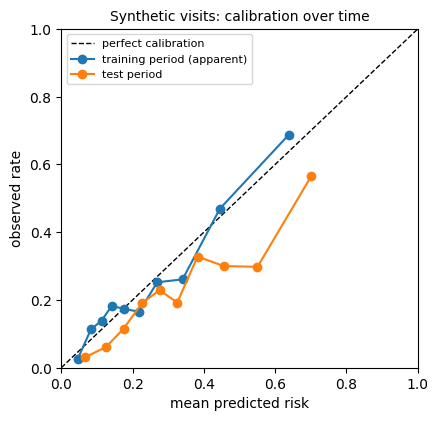

In [9]:
def calibration_in_the_large(y, p):
    y, p = np.asarray(y), np.asarray(p)
    # TODO 2.1: mean predicted risk, observed outcome rate, and observed / mean predicted
    mean_pred = float(p.mean())
    obs = float(y.mean())
    return {"mean_predicted": mean_pred, "observed_rate": obs, "observed_to_expected": obs / mean_pred}


def plot_reliability(curves, title, n_bins=10):
    """curves: dict label -> (y, p). Equal-count bins of predicted risk."""
    fig, ax = plt.subplots(figsize=(4.6, 4.4))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    for label, (y, p) in curves.items():
        frame = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
        frame["bin"] = pd.qcut(frame["p"], q=min(n_bins, len(frame) // 10 or 1), duplicates="drop")
        g = frame.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(g["p"], g["y"], "o-", label=label)
    ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title(title, fontsize=10)
    plt.show()


p_train_fit = temporal_model.predict_proba(train[FEATURES])[:, 1]
print("training period:", calibration_in_the_large(train["admitted_90d"], p_train_fit))
print("test period:    ", calibration_in_the_large(test["admitted_90d"], p_temporal))
plot_reliability({"training period (apparent)": (train["admitted_90d"], p_train_fit),
                  "test period": (test["admitted_90d"], p_temporal)}, "Synthetic visits: calibration over time")

### Exercise 2.2 — Find the cause

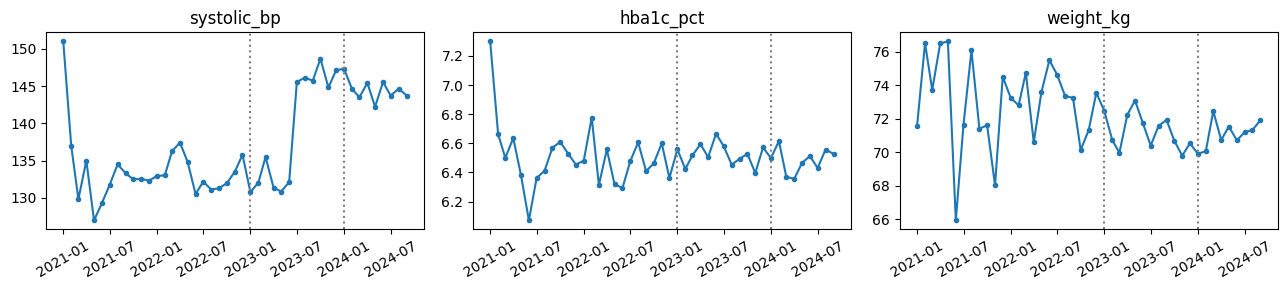

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col in zip(axes, ["systolic_bp", "hba1c_pct", "weight_kg"]):
    # TODO 2.2: plot the monthly mean of `col` against time on `ax`
    monthly = visits.set_index("visit_date")[col].resample("MS").mean()
    ax.plot(monthly.index, monthly.values, marker="o", ms=3)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=30)
    ax.axvline(pd.Timestamp("2023-01-01"), color="grey", ls=":")
    ax.axvline(pd.Timestamp("2024-01-01"), color="grey", ls=":")
plt.tight_layout()
plt.show()

### Exercise 2.3 — Interpret

In [11]:
cal_tr = calibration_in_the_large(train["admitted_90d"], p_train_fit)
cal_te = calibration_in_the_large(test["admitted_90d"], p_temporal)
auc_te = roc_auc_score(test["admitted_90d"], p_temporal)
new_dev = visits["visit_date"] >= "2023-07-01"
sbp_pre = visits.loc[~new_dev, "systolic_bp"].mean(); sbp_post = visits.loc[new_dev, "systolic_bp"].mean()

display(Markdown(f"""
**✍️ Answer 2.3**

1. **Systolic blood pressure** changed, as a step in **July 2023**: the mean recorded value is {sbp_pre:.1f} mm Hg before and {sbp_post:.1f} mm Hg after, about **{sbp_post - sbp_pre:.0f} mm Hg higher**. HbA1c and weight show no such step.
2. The model was trained on 2021–2022 data, where `systolic_bp` was recorded on the old device, and it learned a positive weight for it. After the new device started, every reading is about 12 mm Hg too high, so the model sees patients as hypertensive and assigns more risk, although the patients' true blood pressure (which drives admissions) did not change. Predicted risk therefore rises while the observed rate does not: mean predicted {cal_te['mean_predicted']:.3f} versus observed {cal_te['observed_rate']:.3f} (observed/expected = {cal_te['observed_to_expected']:.2f}, compared with {cal_tr['observed_to_expected']:.2f} in the training period).
3. **AUROC did not reveal it** (test AUROC {auc_te:.3f}). AUROC only measures ranking. A roughly constant upward shift in one input moves most patients' scores in the same direction, so the order of patients barely changes while the absolute risks become wrong. Calibration (calibration-in-the-large, reliability diagram) is what shows the problem.
4. To **detect** such a change: (a) monitor the monthly distribution (mean/SD) of every input, and compare against the training data, and (b) track calibration-in-the-large (observed/expected) on recent patients with known outcomes, with alerts when it leaves an agreed range; audits of equipment or coding changes also help. To **correct** it: fix or adjust the input (subtract the known 12 mm Hg offset, or recalibrate the device), and/or recalibrate or retrain the model on recent data (logistic recalibration of intercept and slope).
"""))


**✍️ Answer 2.3**

1. **Systolic blood pressure** changed, as a step in **July 2023**: the mean recorded value is 132.8 mm Hg before and 145.1 mm Hg after, about **12 mm Hg higher**. HbA1c and weight show no such step.
2. The model was trained on 2021–2022 data, where `systolic_bp` was recorded on the old device, and it learned a positive weight for it. After the new device started, every reading is about 12 mm Hg too high, so the model sees patients as hypertensive and assigns more risk, although the patients' true blood pressure (which drives admissions) did not change. Predicted risk therefore rises while the observed rate does not: mean predicted 0.328 versus observed 0.231 (observed/expected = 0.70, compared with 1.00 in the training period).
3. **AUROC did not reveal it** (test AUROC 0.724). AUROC only measures ranking. A roughly constant upward shift in one input moves most patients' scores in the same direction, so the order of patients barely changes while the absolute risks become wrong. Calibration (calibration-in-the-large, reliability diagram) is what shows the problem.
4. To **detect** such a change: (a) monitor the monthly distribution (mean/SD) of every input, and compare against the training data, and (b) track calibration-in-the-large (observed/expected) on recent patients with known outcomes, with alerts when it leaves an agreed range; audits of equipment or coding changes also help. To **correct** it: fix or adjust the input (subtract the known 12 mm Hg offset, or recalibrate the device), and/or recalibrate or retrain the model on recent data (logistic recalibration of intercept and slope).


**Planted features (revealed after Exercise 2.3):** repeated visits with fixed `height_cm` (memorisation under row-level splits), unrecorded patient-level frailty, and a blood-pressure device change on 1 July 2023 (+12 mm Hg recorded, label depends on the true value).

## Part 3 — External validation on four real hospitals

In [12]:
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def design(df):
    """Core inputs, with chest-pain type and resting ECG one-hot encoded (reference levels dropped)."""
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)


def boot_auroc_ci(y, p, n_boot=1000):
    rng = np.random.default_rng(SEED)
    vals = [roc_auc_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))
            if 0 < y[i].sum() < len(i)]
    return np.percentile(vals, [2.5, 97.5])


def calibration_slope(y, p):
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    return LogisticRegression(penalty=None).fit(logit, y).coef_[0, 0]


def fmt(k, n):
    if n == 0:
        return "undefined"
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {k / n:.2f} ({lo:.2f}-{hi:.2f})"


def validation_report(label, y, p, threshold=0.5):
    y, p = np.asarray(y), np.asarray(p)
    yhat = p >= threshold
    tp, fn = int((yhat & (y == 1)).sum()), int((~yhat & (y == 1)).sum())
    tn, fp = int((~yhat & (y == 0)).sum()), int((yhat & (y == 0)).sum())
    lo, hi = boot_auroc_ci(y, p)
    cal = calibration_in_the_large(y, p)
    return {"site": label, "n": len(y), "with disease": f"{int(y.sum())} ({y.mean():.0%})",
            "AUROC (95% CI)": f"{roc_auc_score(y, p):.2f} ({lo:.2f}-{hi:.2f})",
            "mean predicted": cal["mean_predicted"], "calibration slope": round(calibration_slope(y, p), 2),
            "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp),
            "PPV": fmt(tp, tp + fp), "NPV": fmt(tn, tn + fn)}


dev = SITES["Cleveland"]
heart_model = make_logreg().fit(design(dev), dev["target"])
p_internal = cross_val_predict(make_logreg(), design(dev), dev["target"],
                               cv=StratifiedKFold(10, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]

EXTERNAL = {}
reports = [validation_report("Cleveland (internal, 10-fold CV)", dev["target"], p_internal)]
for site in ["Budapest", "Zurich", "Long Beach"]:
    df = SITES[site]
    keep = df[CORE].notna().all(axis=1)
    print(f"{site}: excluded {int((~keep).sum())} of {len(df)} for missing core inputs")
    EXTERNAL[site] = df[keep].reset_index(drop=True)
    p = heart_model.predict_proba(design(EXTERNAL[site]))[:, 1]
    EXTERNAL[site]["p"] = p
    reports.append(validation_report(site, EXTERNAL[site]["target"], p))

external_table = pd.DataFrame(reports).set_index("site")
external_table.T

Budapest: excluded 2 of 294 for missing core inputs
Zurich: excluded 7 of 123 for missing core inputs
Long Beach: excluded 59 of 200 for missing core inputs


site,"Cleveland (internal, 10-fold CV)",Budapest,Zurich,Long Beach
n,303,292,116,141
with disease,139 (46%),105 (36%),108 (93%),111 (79%)
AUROC (95% CI),0.87 (0.84-0.91),0.88 (0.83-0.92),0.75 (0.59-0.91),0.72 (0.61-0.82)
mean predicted,0.458864,0.410187,0.683543,0.796289
calibration slope,0.88,0.89,0.54,0.48
sensitivity,104/139 = 0.75 (0.67-0.81),81/105 = 0.77 (0.68-0.84),83/108 = 0.77 (0.68-0.84),104/111 = 0.94 (0.88-0.97)
specificity,140/164 = 0.85 (0.79-0.90),156/187 = 0.83 (0.77-0.88),4/8 = 0.50 (0.22-0.78),8/30 = 0.27 (0.14-0.44)
PPV,104/128 = 0.81 (0.74-0.87),81/112 = 0.72 (0.63-0.80),83/87 = 0.95 (0.89-0.98),104/126 = 0.83 (0.75-0.88)
NPV,140/175 = 0.80 (0.73-0.85),156/180 = 0.87 (0.81-0.91),4/29 = 0.14 (0.05-0.31),8/15 = 0.53 (0.30-0.75)


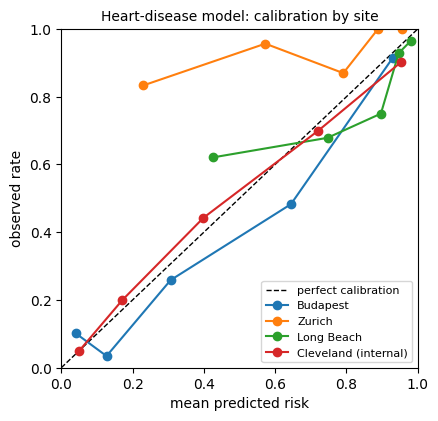

In [13]:
plot_reliability({site: (EXTERNAL[site]["target"], EXTERNAL[site]["p"]) for site in EXTERNAL}
                 | {"Cleveland (internal)": (dev["target"], p_internal)},
                 "Heart-disease model: calibration by site", n_bins=5)

### Exercise 3.1 — Interpret the external validation

In [14]:
def stats(y, p):
    y, p = np.asarray(y), np.asarray(p)
    lo, hi = boot_auroc_ci(y, p)
    return dict(n=len(y), auc=roc_auc_score(y, p), lo=lo, hi=hi, mp=p.mean(), obs=y.mean(),
                slope=calibration_slope(y, p))

S = {"Cleveland": stats(dev["target"], p_internal)}
for s in EXTERNAL:
    S[s] = stats(EXTERNAL[s]["target"], EXTERNAL[s]["p"])
c = S["Cleveland"]
excl = {s: int(SITES[s][CORE].isna().any(axis=1).sum()) for s in EXTERNAL}

disc, cali = [], []
for s in EXTERNAL:
    r = S[s]
    verdict = ("about as good as Cleveland (Cleveland's AUROC lies inside this CI)" if r["lo"] <= c["auc"] <= r["hi"]
               else "clearly worse than Cleveland (the whole CI lies below Cleveland's AUROC)" if r["hi"] < c["auc"]
               else "clearly better than Cleveland (the whole CI lies above)")
    disc.append(f"{s}: AUROC {r['auc']:.2f} ({r['lo']:.2f}-{r['hi']:.2f}), n={r['n']} - {verdict}.")
    level = ("overpredicts risk" if r["mp"] - r["obs"] > 0.03 else
             "underpredicts risk" if r["obs"] - r["mp"] > 0.03 else "has about the right average risk")
    shape = ("predictions too extreme (slope < 1: high risks too high, low risks too low)" if r["slope"] < 0.8 else
             "predictions too modest (slope > 1)" if r["slope"] > 1.2 else "spread of predictions about right (slope near 1)")
    cali.append(f"{s}: {level} (mean predicted {r['mp']:.2f} vs observed {r['obs']:.2f}); slope {r['slope']:.2f}, {shape}.")

z = EXTERNAL["Zurich"]; z_neg = int((z["target"] == 0).sum()); z_hat = z["p"] >= 0.5
z_tn = int((~z_hat & (z["target"] == 0)).sum())
lb = S["Long Beach"]
nl = lambda items: "\n".join("   - " + i for i in items)

display(Markdown(f"""
**✍️ Answer 3.1**

1. Discrimination (Cleveland internal AUROC {c['auc']:.2f}, CI {c['lo']:.2f}-{c['hi']:.2f}):
{nl(disc)}
2. Calibration:
{nl(cali)}
3. Long Beach's *average* predicted risk is {lb['mp']:.2f} against an observed rate of {lb['obs']:.2f}, and the calibration slope is {lb['slope']:.2f}. A slope well below 1 means individual predictions are too extreme: patients given high risk are less likely to have disease than predicted, and those given low risk are more likely to have it. Average calibration can hide this because over- and under-prediction cancel out. Individual risk estimates (and threshold decisions) are therefore unreliable even when the mean looks acceptable.
4. Zurich's specificity rests on only **{z_neg} patients without disease** ({z_tn}/{z_neg} correctly below 0.5, after exclusions). The Wilson interval is very wide, so no firm conclusion about specificity is possible; Zurich has very few non-diseased patients (about {1 - S['Zurich']['obs']:.0%} of its sample), and the data say much more about sensitivity than specificity.
5. Excluded patients for missing core inputs: {', '.join(f"{s} {n}" for s, n in excl.items())}. Missingness is probably not random (e.g. an exercise test or measurement not done because the patient was frail, low-risk or had a different referral pathway), so the remaining patients can differ systematically from the full population (selection bias). That can change prevalence, discrimination and calibration; Long Beach lost the most, so its results are the least generalisable to all its patients.
"""))


**✍️ Answer 3.1**

1. Discrimination (Cleveland internal AUROC 0.87, CI 0.84-0.91):
   - Budapest: AUROC 0.88 (0.83-0.92), n=292 - about as good as Cleveland (Cleveland's AUROC lies inside this CI).
   - Zurich: AUROC 0.75 (0.59-0.91), n=116 - about as good as Cleveland (Cleveland's AUROC lies inside this CI).
   - Long Beach: AUROC 0.72 (0.61-0.82), n=141 - clearly worse than Cleveland (the whole CI lies below Cleveland's AUROC).
2. Calibration:
   - Budapest: overpredicts risk (mean predicted 0.41 vs observed 0.36); slope 0.89, spread of predictions about right (slope near 1).
   - Zurich: underpredicts risk (mean predicted 0.68 vs observed 0.93); slope 0.54, predictions too extreme (slope < 1: high risks too high, low risks too low).
   - Long Beach: has about the right average risk (mean predicted 0.80 vs observed 0.79); slope 0.48, predictions too extreme (slope < 1: high risks too high, low risks too low).
3. Long Beach's *average* predicted risk is 0.80 against an observed rate of 0.79, and the calibration slope is 0.48. A slope well below 1 means individual predictions are too extreme: patients given high risk are less likely to have disease than predicted, and those given low risk are more likely to have it. Average calibration can hide this because over- and under-prediction cancel out. Individual risk estimates (and threshold decisions) are therefore unreliable even when the mean looks acceptable.
4. Zurich's specificity rests on only **8 patients without disease** (4/8 correctly below 0.5, after exclusions). The Wilson interval is very wide, so no firm conclusion about specificity is possible; Zurich has very few non-diseased patients (about 7% of its sample), and the data say much more about sensitivity than specificity.
5. Excluded patients for missing core inputs: Budapest 2, Zurich 7, Long Beach 59. Missingness is probably not random (e.g. an exercise test or measurement not done because the patient was frail, low-risk or had a different referral pathway), so the remaining patients can differ systematically from the full population (selection bias). That can change prevalence, discrimination and calibration; Long Beach lost the most, so its results are the least generalisable to all its patients.


### Exercise 3.2 — Recalibrate the model for Budapest

In [15]:
def logit(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_recalibration(y_fit, p_fit):
    # TODO 3.2: fit LogisticRegression(penalty=None) of y_fit on logit(p_fit);
    #           return a function p_new -> recalibrated probabilities
    lr = LogisticRegression(penalty=None).fit(logit(p_fit), np.asarray(y_fit))
    return lambda p_new: lr.predict_proba(logit(p_new))[:, 1]


bud = EXTERNAL["Budapest"]
fit_half, eval_half = train_test_split(bud, test_size=0.5, stratify=bud["target"], random_state=SEED)
recalibrate = fit_recalibration(fit_half["target"], fit_half["p"])
p_before, p_after = eval_half["p"].to_numpy(), recalibrate(eval_half["p"])

y_eval = eval_half["target"].to_numpy()
print("evaluation half, before:", calibration_in_the_large(y_eval, p_before),
      "| slope", round(calibration_slope(y_eval, p_before), 2), "| AUROC", round(roc_auc_score(y_eval, p_before), 3))
print("evaluation half, after: ", calibration_in_the_large(y_eval, p_after),
      "| slope", round(calibration_slope(y_eval, np.clip(p_after, 1e-6, 1 - 1e-6)), 2),
      "| AUROC", round(roc_auc_score(y_eval, p_after), 3))
check("recalibration changed the predictions", not np.allclose(p_before, p_after))

evaluation half, before: {'mean_predicted': 0.3938031790715844, 'observed_rate': 0.3561643835616438, 'observed_to_expected': 0.9044223167556026} | slope 0.96 | AUROC 0.893
evaluation half, after:  {'mean_predicted': 0.3351491966217308, 'observed_rate': 0.3561643835616438, 'observed_to_expected': 1.0627039752794991} | slope 1.16 | AUROC 0.893
PASS  recalibration changed the predictions


In [16]:
cb = calibration_in_the_large(y_eval, p_before); ca = calibration_in_the_large(y_eval, p_after)
sb = calibration_slope(y_eval, p_before); sa = calibration_slope(y_eval, np.clip(p_after, 1e-6, 1 - 1e-6))
display(Markdown(f"""
**✍️ Answer 3.2**

On the evaluation half, mean predicted risk moved from {cb['mean_predicted']:.3f} to {ca['mean_predicted']:.3f} against an observed rate of {cb['observed_rate']:.3f} (observed/expected {cb['observed_to_expected']:.2f} to {ca['observed_to_expected']:.2f}), and the calibration slope moved from {sb:.2f} to {sa:.2f}. AUROC stays the same ({roc_auc_score(y_eval, p_before):.3f} vs {roc_auc_score(y_eval, p_after):.3f}) because recalibration is a monotonic transformation of the log-odds (new intercept + positive slope), which changes the risk values but not the order of patients. With only {len(fit_half)} patients in the fitting half the two fitted numbers are uncertain and may be overfitted to this half, so the result could change on another sample. Before using the recalibrated model I would require a larger local sample, confidence intervals for the new intercept and slope, a check on a separate or later set of Budapest patients, and then prospective evaluation and monitoring.
"""))


**✍️ Answer 3.2**

On the evaluation half, mean predicted risk moved from 0.394 to 0.335 against an observed rate of 0.356 (observed/expected 0.90 to 1.06), and the calibration slope moved from 0.96 to 1.16. AUROC stays the same (0.893 vs 0.893) because recalibration is a monotonic transformation of the log-odds (new intercept + positive slope), which changes the risk values but not the order of patients. With only 146 patients in the fitting half the two fitted numbers are uncertain and may be overfitted to this half, so the result could change on another sample. Before using the recalibrated model I would require a larger local sample, confidence intervals for the new intercept and slope, a check on a separate or later set of Budapest patients, and then prospective evaluation and monitoring.


## Part 4 — Subgroup audit and error analysis
### Exercise 4.1 — Performance by sex

In [17]:
def subgroup_table(df, y_col, p_col, group_col, threshold=0.5):
    rows = []
    for value, g in df.groupby(group_col):
        y, p = g[y_col].to_numpy(), g[p_col].to_numpy()
        yhat = p >= threshold
        # TODO 4.1: compute tp, fn, tn, fp; append a row with group, n, with disease, AUROC, sensitivity, specificity
        tp, fn = int((yhat & (y == 1)).sum()), int((~yhat & (y == 1)).sum())
        tn, fp = int((~yhat & (y == 0)).sum()), int((yhat & (y == 0)).sum())
        auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
        rows.append({"group": value, "n": len(g), "with disease": int(y.sum()), "AUROC": round(auc, 2),
                     "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp)})
    return pd.DataFrame(rows)


SEX = {0: "women", 1: "men"}
cle = dev.assign(p=p_internal, group=dev["sex"].map(SEX))
display(subgroup_table(cle, "target", "p", "group").assign(site="Cleveland (internal)"))
display(subgroup_table(EXTERNAL["Budapest"].assign(group=EXTERNAL["Budapest"]["sex"].map(SEX)),
                       "target", "p", "group").assign(site="Budapest"))

,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,206,114,0.84,86/114 = 0.75 (0.67-0.82),72/92 = 0.78 (0.69-0.85),Cleveland (internal)
1,women,97,25,0.89,18/25 = 0.72 (0.52-0.86),68/72 = 0.94 (0.87-0.98),Cleveland (internal)


,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,212,93,0.88,75/93 = 0.81 (0.71-0.87),93/119 = 0.78 (0.70-0.85),Budapest
1,women,80,12,0.78,6/12 = 0.50 (0.25-0.75),63/68 = 0.93 (0.84-0.97),Budapest


In [18]:
tc = subgroup_table(cle, "target", "p", "group").set_index("group")
bb = EXTERNAL["Budapest"].assign(group=EXTERNAL["Budapest"]["sex"].map(SEX))
tb = subgroup_table(bb, "target", "p", "group").set_index("group")

def sens_ci(t, g):
    r = t.loc[g]; k = int(round(float(r["sensitivity"].split("/")[0]))); n = int(r["sensitivity"].split("/")[1].split(" ")[0])
    return wilson(k, n)
def overlap(t):
    (a, b), (c_, d_) = sens_ci(t, "women"), sens_ci(t, "men")
    return max(a, c_) <= min(b, d_)
ov_c, ov_b = overlap(tc), overlap(tb)
ov_txt = ("the women's and men's sensitivity intervals overlap at both sites, so the data cannot show a real difference" if ov_c and ov_b
          else "the intervals overlap at only one site (or neither), so any gap is inconsistent and still uncertain given the small numbers")
display(Markdown(f"""
**✍️ Answer 4.1**

The evidence is limited. In Cleveland, women have sensitivity {tc.loc['women','sensitivity']} versus men {tc.loc['men','sensitivity']}; in Budapest, women {tb.loc['women','sensitivity']} versus men {tb.loc['men','sensitivity']}. The women's estimates rest on only **{tc.loc['women','with disease']} diseased women in Cleveland** and **{tb.loc['women','with disease']} in Budapest**, so the Wilson intervals are wide; {ov_txt}. AUROC for women is {tc.loc['women','AUROC']} (Cleveland) and {tb.loc['women','AUROC']} (Budapest). For a referral tool, **equal sensitivity** matters most, since a missed disease case is the costly error (equal specificity and PPV are secondary, and PPV also depends on prevalence, which differs by sex). With these numbers I cannot check it reliably, so I would report the gap as uncertain and collect more data for women before drawing a fairness conclusion.
"""))


**✍️ Answer 4.1**

The evidence is limited. In Cleveland, women have sensitivity 18/25 = 0.72 (0.52-0.86) versus men 86/114 = 0.75 (0.67-0.82); in Budapest, women 6/12 = 0.50 (0.25-0.75) versus men 75/93 = 0.81 (0.71-0.87). The women's estimates rest on only **25 diseased women in Cleveland** and **12 in Budapest**, so the Wilson intervals are wide; the women's and men's sensitivity intervals overlap at both sites, so the data cannot show a real difference. AUROC for women is 0.89 (Cleveland) and 0.78 (Budapest). For a referral tool, **equal sensitivity** matters most, since a missed disease case is the costly error (equal specificity and PPV are secondary, and PPV also depends on prevalence, which differs by sex). With these numbers I cannot check it reliably, so I would report the gap as uncertain and collect more data for women before drawing a fairness conclusion.


### Exercise 4.2 — Look at the errors

In [19]:
bud = EXTERNAL["Budapest"].copy()
bud["error"] = np.select([(bud["target"] == 1) & (bud["p"] < 0.5), (bud["target"] == 0) & (bud["p"] >= 0.5)],
                         ["false negative", "false positive"], default="correct")
print(bud["error"].value_counts())

# TODO 4.2: build a table of chest-pain type proportions within each error group
#           Hint: pd.crosstab(bud["error"], bud["cp"], normalize="index")
cp_by_error = pd.crosstab(bud["error"], bud["cp"], normalize="index").round(2)
cp_by_error

error
correct           237
false positive     31
false negative     24
Name: count, dtype: int64


cp,1,2,3,4
error,,,,
correct,0.03,0.42,0.17,0.38
false negative,0.12,0.12,0.42,0.33
false positive,0.00,0.10,0.10,0.81


In [20]:
cols = CORE + ["target", "p"]
print("Ten false negatives with the lowest predicted risk:")
display(bud[bud["error"] == "false negative"].sort_values("p")[cols].head(10).round(2))

Ten false negatives with the lowest predicted risk:


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
255,47,0,3,135.0,170.0,0.0,0.0,0.0,1,0.02
189,34,1,1,140.0,180.0,0.0,0.0,0.0,1,0.05
209,49,1,3,115.0,175.0,0.0,0.0,0.0,1,0.06
208,49,0,3,160.0,156.0,0.0,1.0,0.0,1,0.07
269,56,0,2,120.0,150.0,0.0,1.0,0.0,1,0.07
211,50,0,3,140.0,140.0,1.0,0.0,0.0,1,0.08
228,43,1,1,120.0,155.0,0.0,0.0,1.0,1,0.10
190,35,1,2,110.0,140.0,0.0,0.0,0.0,1,0.12
254,46,1,1,140.0,175.0,0.0,2.0,0.0,1,0.21
288,54,0,3,130.0,100.0,1.0,0.0,1.0,1,0.22


In [21]:
fn = bud[bud["error"] == "false negative"]
n_fn = len(fn)
cp_fn = fn["cp"].value_counts(normalize=True); cp_all = bud["cp"].value_counts(normalize=True)
top_cp = cp_fn.idxmax()
CP_NAME = {1: "typical angina", 2: "atypical angina", 3: "non-anginal pain", 4: "asymptomatic"}
coef = pd.Series(heart_model[-1].coef_[0], index=design(dev).columns)
cp4_coef = coef.get("cp_4", float("nan"))
women_fn = (fn["sex"] == 0).mean(); women_all = (bud["sex"] == 0).mean()
noex_fn = (fn["exang"] == 0).mean(); noex_all = (bud["exang"] == 0).mean()
display(Markdown(f"""
**✍️ Answer 4.2**

Budapest at threshold 0.5 has {n_fn} false negatives. Their commonest chest-pain type is **{CP_NAME.get(int(top_cp), top_cp)} (cp={int(top_cp)}): {cp_fn.max():.0%} of false negatives versus {cp_all.get(top_cp, 0):.0%} of all Budapest patients** (full breakdown in the table above). Other features: {women_fn:.0%} of false negatives are women (vs {women_all:.0%} of all Budapest patients) and {noex_fn:.0%} had no exercise-induced angina (vs {noex_all:.0%} overall). The model gives each chest-pain category a fixed weight learned in Cleveland (coefficients on the scaled inputs: cp_2 {coef.get('cp_2', float('nan')):.2f}, cp_3 {coef.get('cp_3', float('nan')):.2f}, cp_4 {coef.get('cp_4', float('nan')):.2f}, relative to typical angina), so it relies heavily on chest-pain type. This is the dependence Session 5 highlighted for the chest-pain coefficient: if the link between chest-pain type and disease differs at Budapest, patients in the over-represented group above are systematically scored too low (missed) or too high. I would **not widen the intended use**; I would first collect more local data, check whether chest-pain coding and referral practice differ between sites, and recalibrate or refit before any use as a rule-out tool.
"""))


**✍️ Answer 4.2**

Budapest at threshold 0.5 has 24 false negatives. Their commonest chest-pain type is **non-anginal pain (cp=3): 42% of false negatives versus 18% of all Budapest patients** (full breakdown in the table above). Other features: 25% of false negatives are women (vs 27% of all Budapest patients) and 79% had no exercise-induced angina (vs 70% overall). The model gives each chest-pain category a fixed weight learned in Cleveland (coefficients on the scaled inputs: cp_2 0.24, cp_3 0.08, cp_4 1.06, relative to typical angina), so it relies heavily on chest-pain type. This is the dependence Session 5 highlighted for the chest-pain coefficient: if the link between chest-pain type and disease differs at Budapest, patients in the over-represented group above are systematically scored too low (missed) or too high. I would **not widen the intended use**; I would first collect more local data, check whether chest-pain coding and referral practice differ between sites, and recalibrate or refit before any use as a rule-out tool.


## Part 5 — Validation report and reflection

In [22]:
def row(label):
    return external_table.loc[label]

cl, bu = row("Cleveland (internal, 10-fold CV)"), row("Budapest")
tp_ = lambda s: s
display(Markdown(f"""
### Validation report: heart-disease logistic regression model

**Model and intended use.** Logistic regression on 8 routine inputs (age, sex, chest-pain type, resting BP, max heart rate, exercise angina, ST depression, resting ECG) to estimate probability of coronary disease; research/teaching use only, not a clinical tool.

**Development data.** Cleveland, {len(dev)} patients ({int(dev['target'].sum())} with disease, {dev['target'].mean():.0%}); period not given in the files; outcome = >50% vessel narrowing on angiography.

**Validation performed.** Cleveland 10-fold stratified CV; external testing at Budapest, Zurich and Long Beach after excluding patients with missing core inputs ({', '.join(f"{s} {n}" for s, n in excl.items())}).

**Discrimination and calibration.** AUROC (95% CI): Cleveland {cl['AUROC (95% CI)']}, Budapest {bu['AUROC (95% CI)']}, Zurich {row('Zurich')['AUROC (95% CI)']}, Long Beach {row('Long Beach')['AUROC (95% CI)']}. Calibration slopes: Cleveland {cl['calibration slope']}, Budapest {bu['calibration slope']}, Zurich {row('Zurich')['calibration slope']}, Long Beach {row('Long Beach')['calibration slope']}; mean predicted risk was {bu['mean predicted']:.2f} in Budapest (observed {S['Budapest']['obs']:.2f}), {row('Long Beach')['mean predicted']:.2f} in Long Beach (observed {S['Long Beach']['obs']:.2f}).

**Threshold performance (0.5).** Cleveland: sensitivity {cl['sensitivity']}, specificity {cl['specificity']}. Budapest: sensitivity {bu['sensitivity']}, specificity {bu['specificity']}. Zurich's specificity rests on very few non-diseased patients.

**Subgroups.** Women: sensitivity {tc.loc['women','sensitivity']} (Cleveland, {tc.loc['women','with disease']} diseased women) and {tb.loc['women','sensitivity']} (Budapest, {tb.loc['women','with disease']}); intervals are too wide to conclude.

**Known failure modes.** Site-dependent calibration (over/under-prediction, slope far from 1 at some sites); missed disease with {CP_NAME.get(int(top_cp), top_cp)} chest pain in Budapest; exclusions may bias results; small samples.

**Recommendation.** Not for clinical use. Use only after local recalibration on adequate data, a subgroup check, and prospective evaluation with monitoring.
"""))


### Validation report: heart-disease logistic regression model

**Model and intended use.** Logistic regression on 8 routine inputs (age, sex, chest-pain type, resting BP, max heart rate, exercise angina, ST depression, resting ECG) to estimate probability of coronary disease; research/teaching use only, not a clinical tool.

**Development data.** Cleveland, 303 patients (139 with disease, 46%); period not given in the files; outcome = >50% vessel narrowing on angiography.

**Validation performed.** Cleveland 10-fold stratified CV; external testing at Budapest, Zurich and Long Beach after excluding patients with missing core inputs (Budapest 2, Zurich 7, Long Beach 59).

**Discrimination and calibration.** AUROC (95% CI): Cleveland 0.87 (0.84-0.91), Budapest 0.88 (0.83-0.92), Zurich 0.75 (0.59-0.91), Long Beach 0.72 (0.61-0.82). Calibration slopes: Cleveland 0.88, Budapest 0.89, Zurich 0.54, Long Beach 0.48; mean predicted risk was 0.41 in Budapest (observed 0.36), 0.80 in Long Beach (observed 0.79).

**Threshold performance (0.5).** Cleveland: sensitivity 104/139 = 0.75 (0.67-0.81), specificity 140/164 = 0.85 (0.79-0.90). Budapest: sensitivity 81/105 = 0.77 (0.68-0.84), specificity 156/187 = 0.83 (0.77-0.88). Zurich's specificity rests on very few non-diseased patients.

**Subgroups.** Women: sensitivity 18/25 = 0.72 (0.52-0.86) (Cleveland, 25 diseased women) and 6/12 = 0.50 (0.25-0.75) (Budapest, 12); intervals are too wide to conclude.

**Known failure modes.** Site-dependent calibration (over/under-prediction, slope far from 1 at some sites); missed disease with non-anginal pain chest pain in Budapest; exclusions may bias results; small samples.

**Recommendation.** Not for clinical use. Use only after local recalibration on adequate data, a subgroup check, and prospective evaluation with monitoring.


**✍️ Reflection**

The easiest mistake to make unnoticed is the **row-level split of repeated-measures data** (Part 1): the code runs, the AUROC looks impressive, and nothing warns you that patients leaked between training and test. Calibration drift (Part 2) is also silent, but at least a calibration check exposes it. The protecting habit is to **ask "what is the unit of use?" before splitting** (a new patient, a future date, a new hospital), split by that unit with `GroupKFold` or a temporal/external split, and always report calibration and uncertainty alongside AUROC.